In [ ]:
import os
import shutil

# Faixas originais
healthy_dirs = [
    '/kaggle/input/plantifydr-dataset/PlantDiseasesDataset/Strawberry/train/Strawberry Healthy',
    '/kaggle/input/images-of-strawberry-leaves-for-tipburn-detection/dataset - strawberry leaves/healthy'
]

unhealthy_dirs = [
    '/kaggle/input/plantifydr-dataset/PlantDiseasesDataset/Strawberry/train/Strawberry Leaf scorch',
    '/kaggle/input/images-of-strawberry-leaves-for-tipburn-detection/dataset - strawberry leaves/Calciumdeficiency'
]

# Novos caminhos para salvar arquivos
os.makedirs('/kaggle/working/Healthy', exist_ok=True)
os.makedirs('/kaggle/working/UnHealthy', exist_ok=True)

# Função de cópia de arquivos
def copy_images(source_dirs, target_dir):
    for src_dir in source_dirs:
        for filename in os.listdir(src_dir):
            src_path = os.path.join(src_dir, filename)
            dst_path = os.path.join(target_dir, filename)
            if os.path.isfile(src_path):  # Certifique-se de que seja uma imagem.
                shutil.copy2(src_path, dst_path)

# Copiando imagens
copy_images(healthy_dirs, '/kaggle/working/Healthy')
copy_images(unhealthy_dirs, '/kaggle/working/UnHealthy')

print("Imagens mescladas com sucesso ✅")


In [ ]:
def rename_images_in_folder(folder_path, label):
    count = 0
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)

        if os.path.isfile(file_path):
            # Extraia a extensão (.jpg, .png, ...)
            ext = os.path.splitext(filename)[1]
            new_name = f"{label}_{count}{ext}"
            new_path = os.path.join(folder_path, new_name)

            os.rename(file_path, new_path)
            count += 1

# Renomeação
rename_images_in_folder('/kaggle/working/Healthy', label='0')
rename_images_in_folder('/kaggle/working/UnHealthy', label='1')

print("✅ Imagens renomeadas com sucesso")

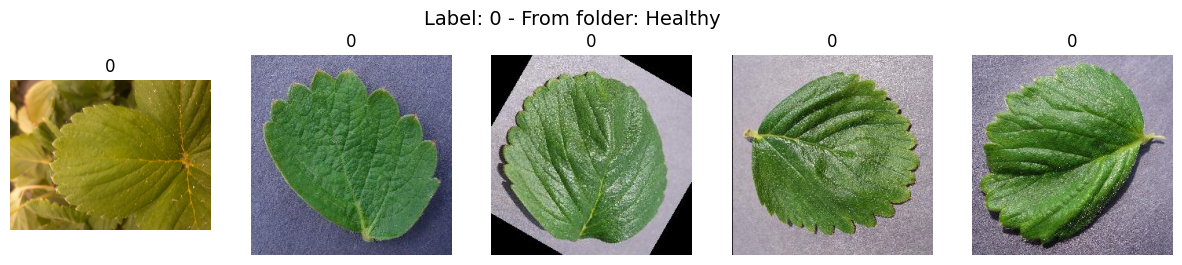

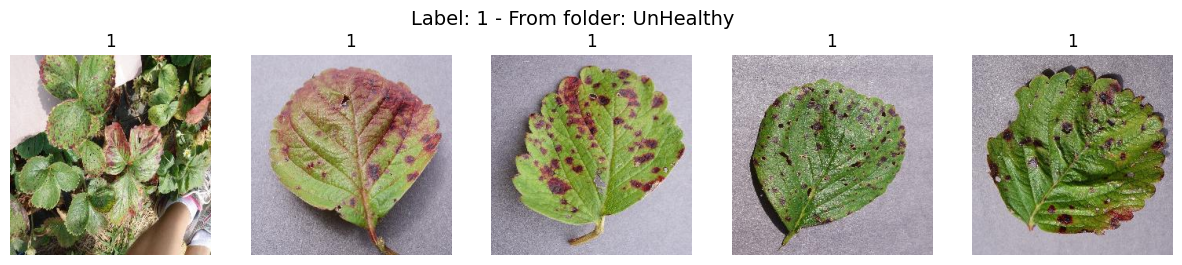

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

def show_sample_images_with_labels(folder_path, label_value, num_images=5):
    images = os.listdir(folder_path)[:num_images]
    plt.figure(figsize=(15, 3))
    for i, img_name in enumerate(images):
        img_path = os.path.join(folder_path, img_name)
        image = Image.open(img_path)
        plt.subplot(1, num_images, i+1)
        plt.imshow(image)
        plt.axis('off')
        plt.title(str(label_value))
    plt.suptitle(f"Label: {label_value} - From folder: {os.path.basename(folder_path)}", fontsize=14)
    plt.show()

# Exibindo imagens da classe Saudável (label = 0)
show_sample_images_with_labels('/kaggle/working/Healthy', label_value=0)

# Exibir imagens da classe NãoSaudável (label = 1)
show_sample_images_with_labels('/kaggle/working/UnHealthy', label_value=1)

In [ ]:
healthy_dir = '/kaggle/working/Healthy'
unhealthy_dir = '/kaggle/working/UnHealthy'

def count_images(folder_path):
    return len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])

healthy_count = count_images(healthy_dir)
unhealthy_count = count_images(unhealthy_dir)

print(f"Numero de Imagens Healthy (0): {healthy_count}")
print(f"Numero de Imagens UnHealthy (1): {unhealthy_count}")


In [ ]:
import os
import random

unhealthy_dir = '/kaggle/working/UnHealthy'
images = [img for img in os.listdir(unhealthy_dir) if os.path.isfile(os.path.join(unhealthy_dir, img))]

# Número de imagens a serem excluídas
extra_count = len(images) - 3445

# Selecionando aleatoriamente as imagens a serem excluídas
images_to_delete = random.sample(images, extra_count)

# Apagar fotos
for img_name in images_to_delete:
    os.remove(os.path.join(unhealthy_dir, img_name))

print(f"✅ imagem removida da categoria Não Saudável. Agora o número de imagens em cada categoria é igual {extra_count} .")


In [ ]:
import os
import shutil
import random

def split_data(source_dir, dest_base_dir, label_name, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    images = os.listdir(source_dir)
    images = [img for img in images if os.path.isfile(os.path.join(source_dir, img))]
    random.shuffle(images)

    total = len(images)
    train_end = int(train_ratio * total)
    val_end = train_end + int(val_ratio * total)

    splits = {
        'train': images[:train_end],
        'val': images[train_end:val_end],
        'test': images[val_end:]
    }

    for split_name, split_images in splits.items():
        split_folder = os.path.join(dest_base_dir, split_name, label_name)
        os.makedirs(split_folder, exist_ok=True)

        for img_name in split_images:
            src_path = os.path.join(source_dir, img_name)
            dst_path = os.path.join(split_folder, img_name)
            shutil.copy2(src_path, dst_path)

# Identificação da rota
healthy_dir = '/kaggle/working/Healthy'
unhealthy_dir = '/kaggle/working/UnHealthy'
base_output_dir = '/kaggle/working/split_dataset'

# Divisão dos dados
split_data(healthy_dir, base_output_dir, label_name='0')  # Healthy => label 0
split_data(unhealthy_dir, base_output_dir, label_name='1')  # UnHealthy => label 1

print("✅ Divisão dos dados em Train / Val / Test concluída com sucesso")

In [ ]:
import os
import shutil
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Divição dos dados em conjuntos de treino, validação e teste.
def split_data(source_dir, dest_base_dir, label_name, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    images = os.listdir(source_dir)
    images = [img for img in images if os.path.isfile(os.path.join(source_dir, img))]
    random.shuffle(images)

    total = len(images)
    train_end = int(train_ratio * total)
    val_end = train_end + int(val_ratio * total)

    splits = {
        'train': images[:train_end],
        'val': images[train_end:val_end],
        'test': images[val_end:]
    }

    for split_name, split_images in splits.items():
        split_folder = os.path.join(dest_base_dir, split_name, label_name)
        os.makedirs(split_folder, exist_ok=True)

        for img_name in split_images:
            src_path = os.path.join(source_dir, img_name)
            dst_path = os.path.join(split_folder, img_name)
            shutil.copy2(src_path, dst_path)

# Identificação da rota
healthy_dir = '/kaggle/working/Healthy'
unhealthy_dir = '/kaggle/working/UnHealthy'
base_output_dir = '/kaggle/working/split_dataset'

# Divisão dos dados
split_data(healthy_dir, base_output_dir, label_name='0')  # Healthy => label 0
split_data(unhealthy_dir, base_output_dir, label_name='1')  # UnHealthy => label 1

# 2. preparação dos dados utilizando ImageDataGenerator sem Data Augmentation

train_dir = os.path.join(base_output_dir, 'train')
val_dir = os.path.join(base_output_dir, 'val')
test_dir = os.path.join(base_output_dir, 'test')


2025-05-12 13:09:29.704335: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747055369.903185      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747055369.958771      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 6273 images belonging to 2 classes.
Found 1912 images belonging to 2 classes.
Found 1919 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configurando o ImageDataGenerators
train_datagen = ImageDataGenerator(rescale=1./255)  # apenas Normalization
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Baixar dados de treinamento
train_generator = train_datagen.flow_from_directory(
    train_dir,  # Caminho dos Dados de Treinamento
    target_size=(150, 150),  # Alterar tamanho
    batch_size=32,  # Tamanho do lote
    class_mode='binary'  # Classificação binária
)

# Tamanho dos dados de validação (validation)
val_generator = val_datagen.flow_from_directory(
    val_dir,  # Caminho dos Dados de Validação
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

# Tamanho dos dados de teste
test_generator = test_datagen.flow_from_directory(
    test_dir,  # Caminho dos Dados de Teste
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)


Found 6273 images belonging to 2 classes.
Found 1912 images belonging to 2 classes.
Found 1919 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras import regularizers

input_shape = (150, 150, 3)

model = Sequential()

# Camadas Conv2D com um número maior de filtros
model.add(Conv2D(512, (3, 3), padding='same', input_shape=input_shape, activation='relu'))
model.add(Conv2D(512, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(512, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Camadas Conv2D com um número menor de filtros
model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Camadas Conv2D com número menor de filtros
model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Camada Conv2D última com filtro menor
model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten
model.add(Flatten())

# Camada Dense com Regularizer e Dropout
model.add(Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dropout(0.5))

# Camada de classificação
model.add(Dense(1, activation='sigmoid'))

# Tamanho dos dados de teste
model.compile(optimizer=Adamax(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)                   │ (None, 150, 150, 512)       │          14,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 150, 150, 512)       │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_18 (Conv2D)                   │ (None, 150, 150, 512)       │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 75, 75, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_19 (Conv2D)                   │ (None, 75, 75, 256)         │       1,179,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_20 (Conv2D)                   │ (None, 75, 75, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 37, 37, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 37, 37, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_21 (Conv2D)                   │ (None, 37, 37, 128)         │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_22 (Conv2D)                   │ (None, 37, 37, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 18, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 18, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_23 (Conv2D)                   │ (None, 18, 18, 64)          │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 9, 9, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 5184)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │       1,327,360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,347,969 (31.84 MB)

 Trainable params: 8,347,969 (31.84 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Configurando um model checkpoint para salvar o melhor modelo com base na
# validation accuracy
model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

In [28]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1747056196.723423     147 service.cc:148] XLA service 0x79b6744154c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1747056196.724506     147 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1747056197.266220     147 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-05-12 13:23:26.517027: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng20{k2=0,k4=2,k5=1,k6=0,k7=0} for conv (f32[32,512,150,150]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,512,150,150]{3,2,1,0}, f32[512,512,3,3]{3,

197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6443 - loss: 2.6834

2025-05-12 13:28:28.650592: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng20{k2=0,k4=2,k5=1,k6=0,k7=0} for conv (f32[32,512,150,150]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,512,150,150]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-05-12 13:28:28.849370: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.198888698s
Trying algorithm eng20{k2=0,k4=2,k5=1,k6=0,k7=0} for conv (f32[32,512,150,150]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,512,150,150]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_

197/197 ━━━━━━━━━━━━━━━━━━━━ 434s 2s/step - accuracy: 0.6451 - loss: 2.6789 - val_accuracy: 0.9315 - val_loss: 1.0280
Epoch 2/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 282s 1s/step - accuracy: 0.9681 - loss: 0.8473 - val_accuracy: 0.9796 - val_loss: 0.5716
Epoch 3/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 278s 1s/step - accuracy: 0.9709 - loss: 0.5572 - val_accuracy: 0.9864 - val_loss: 0.3886
Epoch 4/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 283s 1s/step - accuracy: 0.9744 - loss: 0.3907 - val_accuracy: 0.9833 - val_loss: 0.2872
Epoch 5/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 275s 1s/step - accuracy: 0.9860 - loss: 0.2680 - val_accuracy: 0.9854 - val_loss: 0.2100
Epoch 6/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 288s 1s/step - accuracy: 0.9823 - loss: 0.2045 - val_accuracy: 0.9874 - val_loss: 0.1535
Epoch 7/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 275s 1s/step - accuracy: 0.9866 - loss: 0.1415 - val_accuracy: 0.9885 - val_loss: 0.1087
Epoch 8/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 277s 1s/step - accuracy: 0.9877 - loss: 0.1077 - val_accuracy: 0.991

<Figure size 2000x800 with 0 Axes>

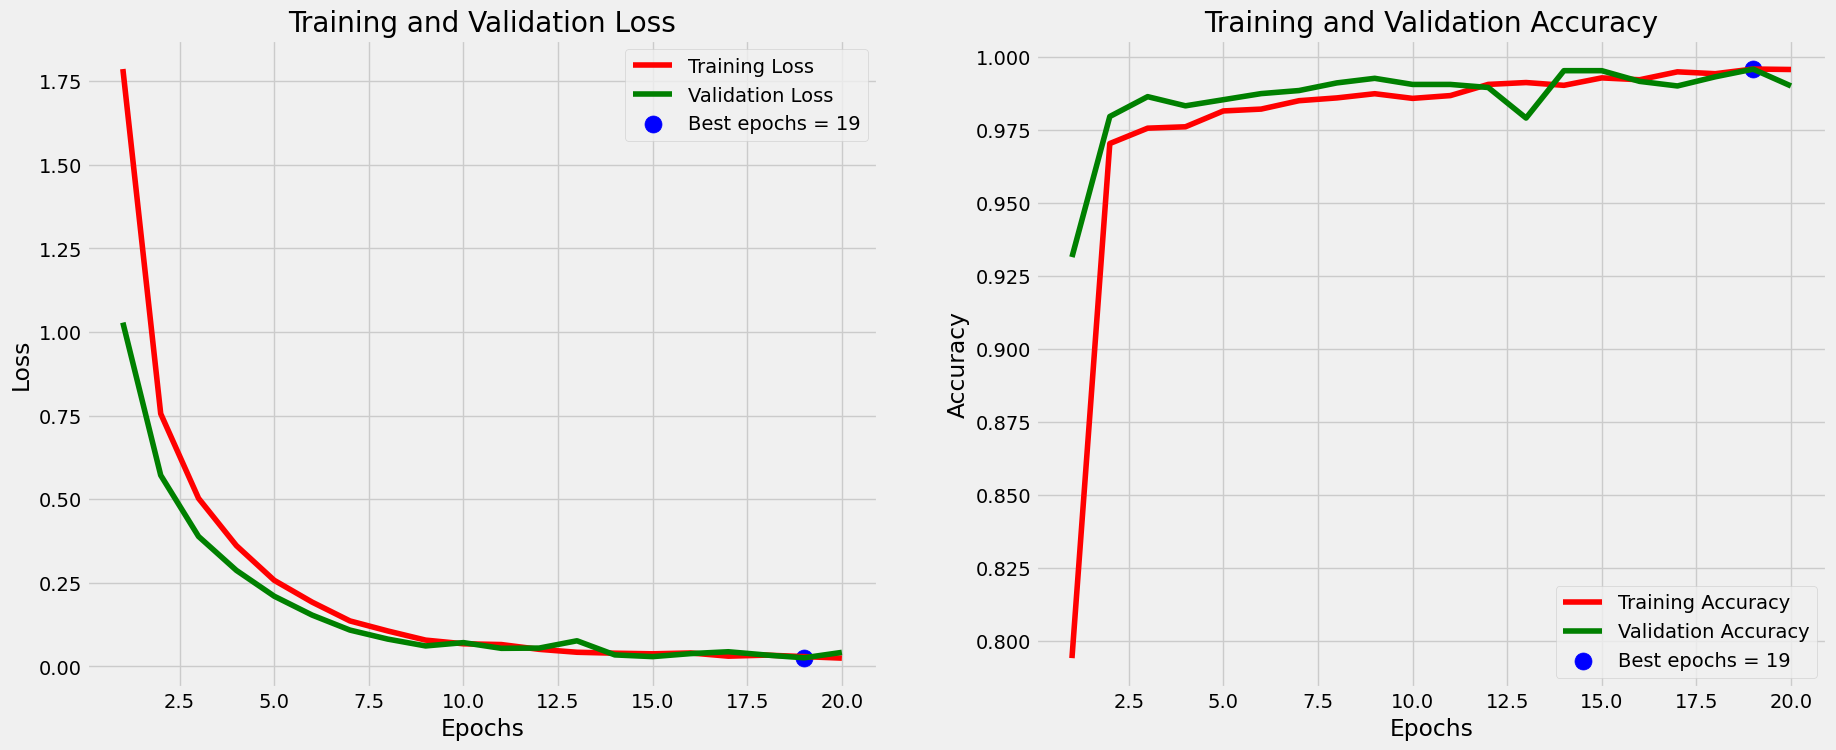

In [30]:
import numpy as np

train_acc = history.history['accuracy']
train_loss = history.history['loss']

val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]

index_acc = np.argmax(val_acc)
val_highest = val_acc[index_acc]

Epochs = [i+1 for i in range(len(train_acc))]

loss_label = f'Best epochs = {str(index_loss +1)}'
acc_label = f'Best epochs = {str(index_acc + 1)}'

#Training history

plt.figure(figsize= (20,8))
plt.style.use('fivethirtyeight')

plt.figure(figsize= (20,8))
plt.style.use('fivethirtyeight')

plt.subplot(1,2,1)
plt.plot(Epochs , train_loss , 'r' , label = 'Training Loss')
plt.plot(Epochs , val_loss , 'g' , label = 'Validation Loss')
plt.scatter(index_loss + 1 , val_lowest , s = 150 , c = 'blue',label = loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs , train_acc , 'r' , label = 'Training Accuracy')
plt.plot(Epochs , val_acc , 'g' , label = 'Validation Accuracy')
plt.scatter(index_acc + 1 , val_highest , s = 150 , c = 'blue',label = acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout
plt.show();

In [32]:
# Evaluate the model on the training set
train_score = model.evaluate(train_generator)
print(f"Training Loss: {train_score[0]}, Training Accuracy: {train_score[1]}")

# Evaluate the model on the validation set
valid_score = model.evaluate(val_generator)
print(f"Validation Loss: {valid_score[0]}, Validation Accuracy: {valid_score[1]}")

# Evaluate the model on the test set
test_score = model.evaluate(test_generator)
print(f"Test Loss: {test_score[0]}, Test Accuracy: {test_score[1]}")

197/197 ━━━━━━━━━━━━━━━━━━━━ 211s 1s/step - accuracy: 0.9985 - loss: 0.0195
Training Loss: 0.019801869988441467, Training Accuracy: 0.9984058737754822
60/60 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.9940 - loss: 0.0291
Validation Loss: 0.025823060423135757, Validation Accuracy: 0.9958158731460571


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


59/60 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9957 - loss: 0.0249

2025-05-12 15:13:37.372401: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng20{k2=0,k4=2,k5=1,k6=0,k7=0} for conv (f32[31,512,150,150]{3,2,1,0}, u8[0]{0}) custom-call(f32[31,512,150,150]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-05-12 15:13:37.538774: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.166499035s
Trying algorithm eng20{k2=0,k4=2,k5=1,k6=0,k7=0} for conv (f32[31,512,150,150]{3,2,1,0}, u8[0]{0}) custom-call(f32[31,512,150,150]{3,2,1,0}, f32[512,512,3,3]{3,2,1,0}, f32[512]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_

60/60 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.9956 - loss: 0.0250
Test Loss: 0.028370346873998642, Test Accuracy: 0.9942678213119507
